# Bank Marketing Subscription Prediction

**Problem:** predict whether a customer subscribed to a term deposit (`y`) from information available before a marketing call. This is binary classification.

Questions: (1) Can pre-call attributes predict subscription? (2) Which model performs best across suitable metrics, relative to a majority baseline? (3) Which features contribute most?

The notebook uses only the provided `bank-full (1).csv` (semicolon delimited) and never modifies it. The data appears to be the Bank Marketing dataset from a Portuguese bank campaign. Original source: [UCI Machine Learning Repository, Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing). Associated study: Moro, Cortez, and Rita (2014), DOI 10.1016/j.dss.2014.03.001.

We exclude `duration` from predictive features because call length is only known during/after a call; it cannot help choose whom to contact beforehand. We still examine it in EDA. This leaves 15 input features for modeling.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
RANDOM_STATE=42
sns.set_theme(style='whitegrid')


## 1. Load and audit
`unknown` is an explicit dataset category, not a blank cell. The value `pdays = -1` means the customer was not previously contacted; it is retained as a meaningful sentinel.

In [2]:
DATA_PATH=Path('bank-full (1).csv')
if not DATA_PATH.exists(): raise FileNotFoundError('Place bank-full (1).csv beside this notebook.')
df=pd.read_csv(DATA_PATH, sep=';')
print('Shape:', df.shape, '| Target: y | Independent columns:', df.shape[1]-1)
display(df.head(), df.dtypes.rename('dtype').to_frame())
print('Missing values:'); display(df.isna().sum().to_frame('count'))
print('Exact duplicate rows:', df.duplicated().sum())
display(df.describe(include='all').T)
print('Target distribution:'); display(pd.DataFrame({'count':df.y.value_counts(),'share':df.y.value_counts(normalize=True)}))


Shape: (45211, 17) | Target: y | Independent columns: 16


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


Missing values:


,count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Target distribution:


,count,share
y,,
no,39922,0.883015
yes,5289,0.116985


## 2. EDA
IQR flags are a screening aid, not proof of bad data. Valid extreme values are retained. Numeric fields include `age`, `balance`, `day`, `duration`, `campaign`, `pdays`, and `previous`; remaining fields are categorical.

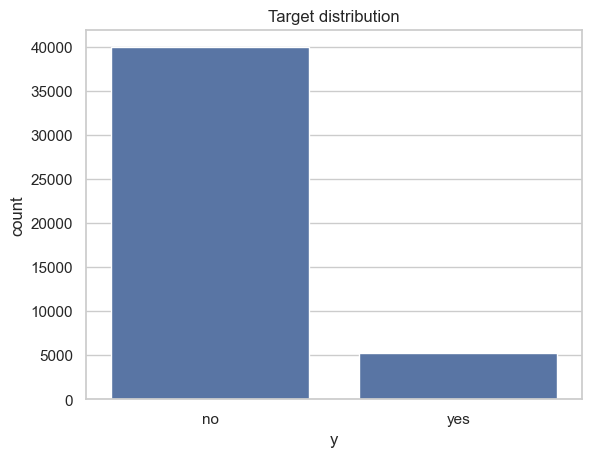

Positive class share: 11.7%; accuracy alone can be misleading.


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


,IQR flagged rows
numeric feature,
age,487
balance,4729
day,0
duration,3235
campaign,3064
pdays,8257
previous,8257


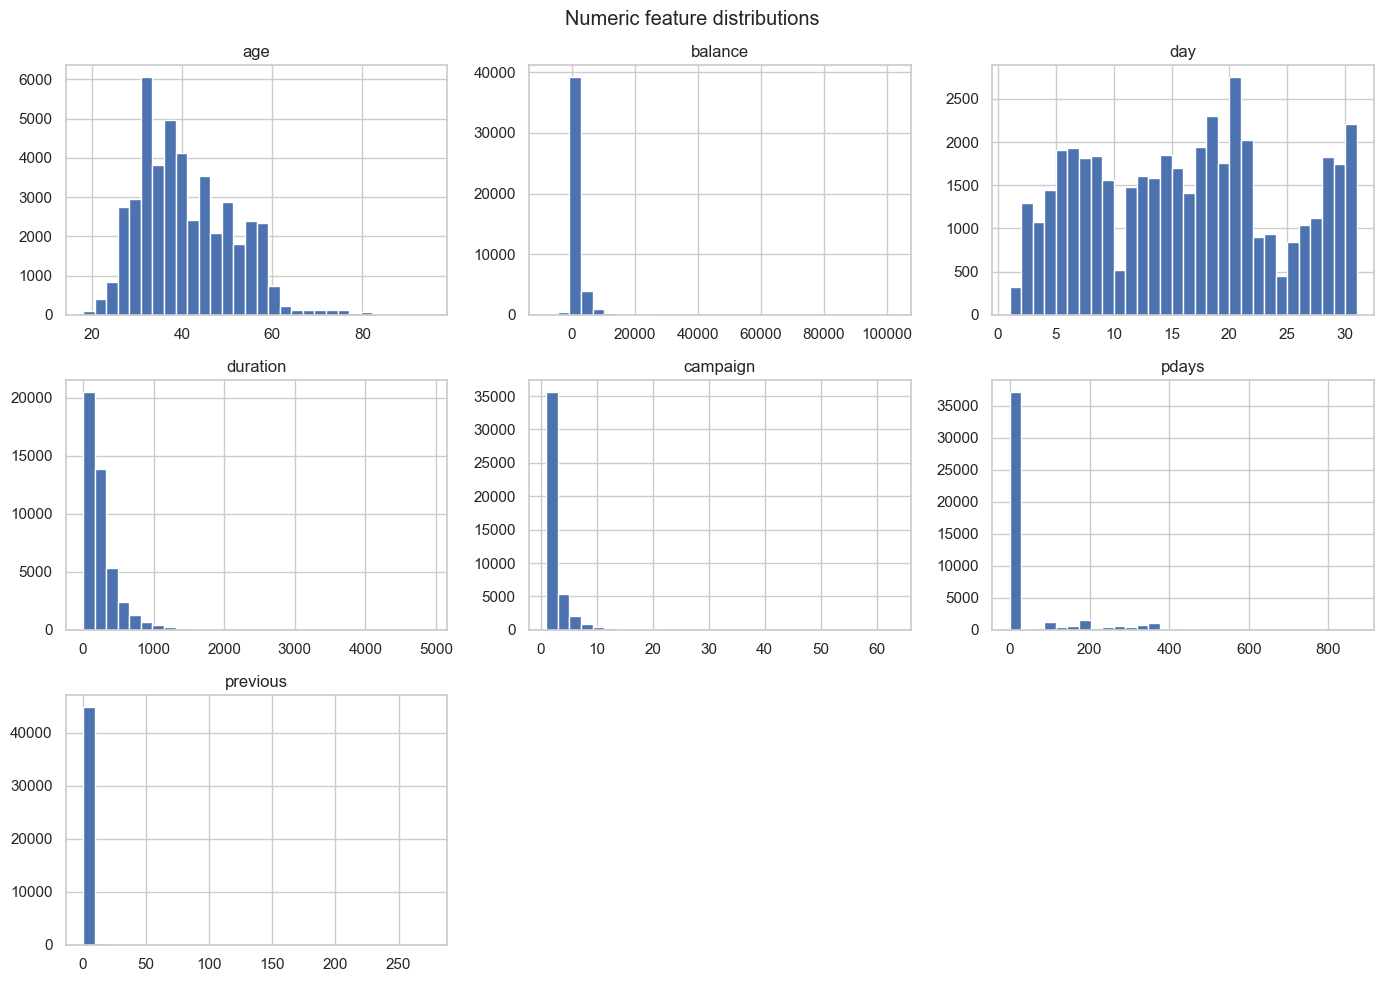

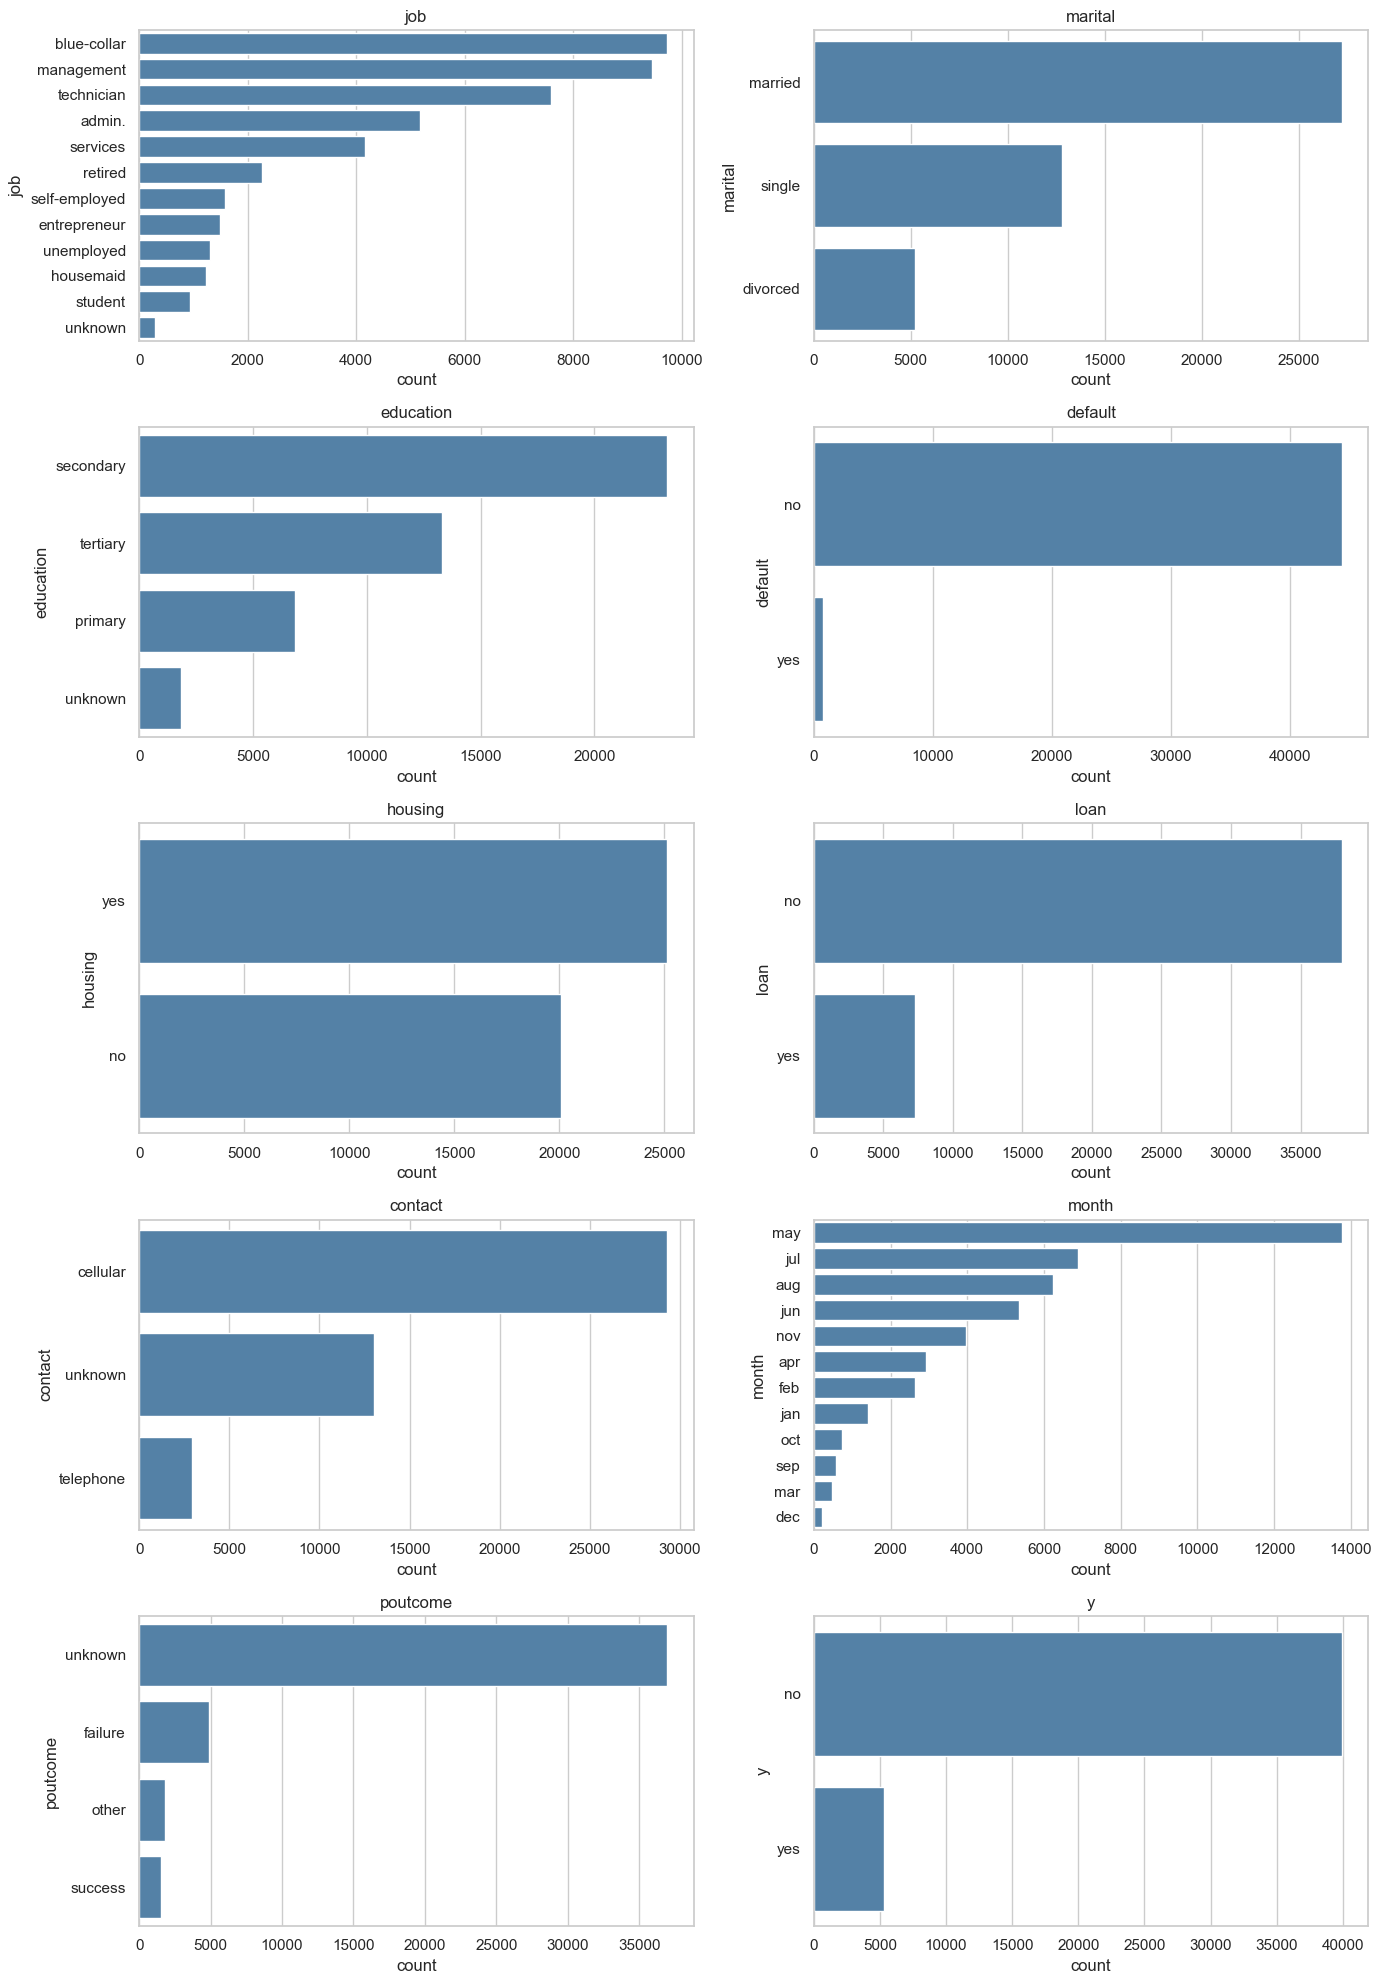

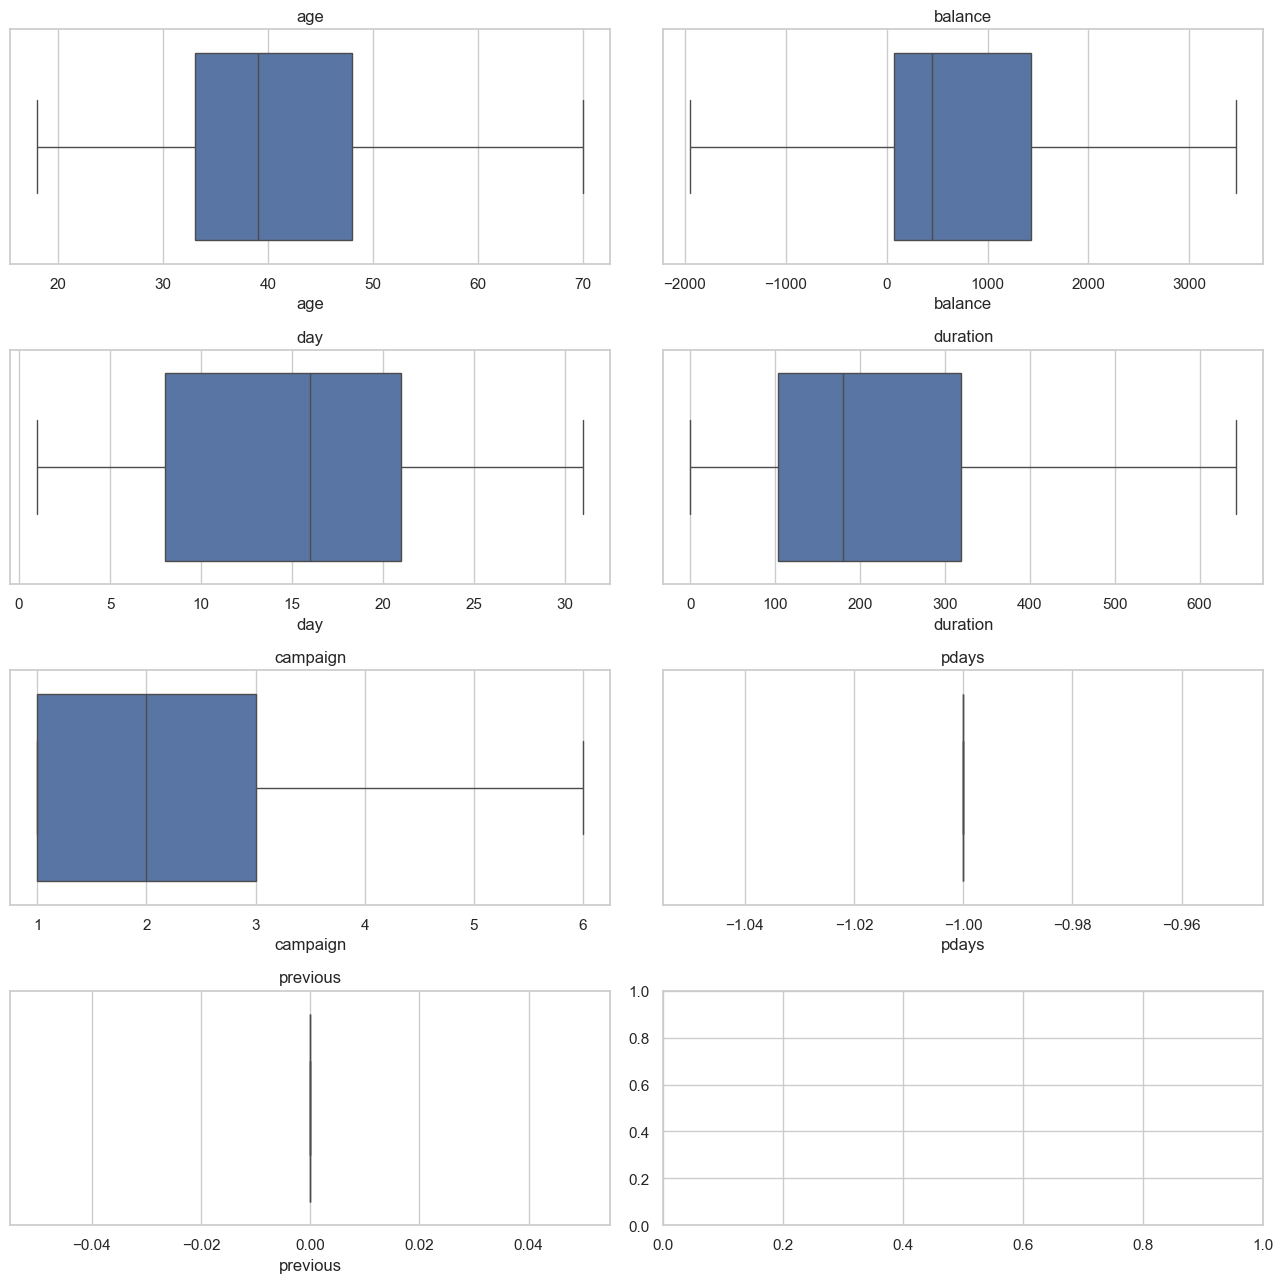

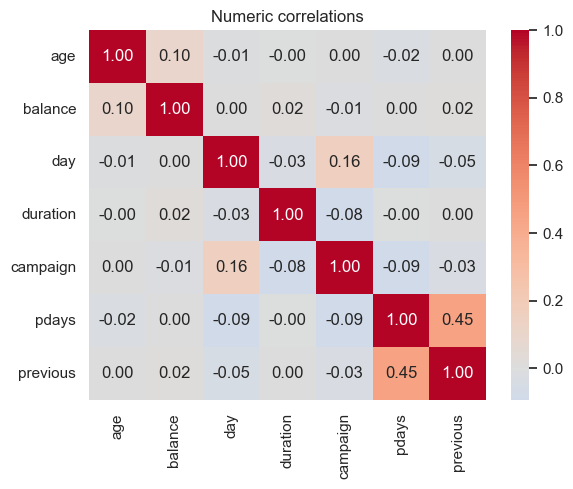

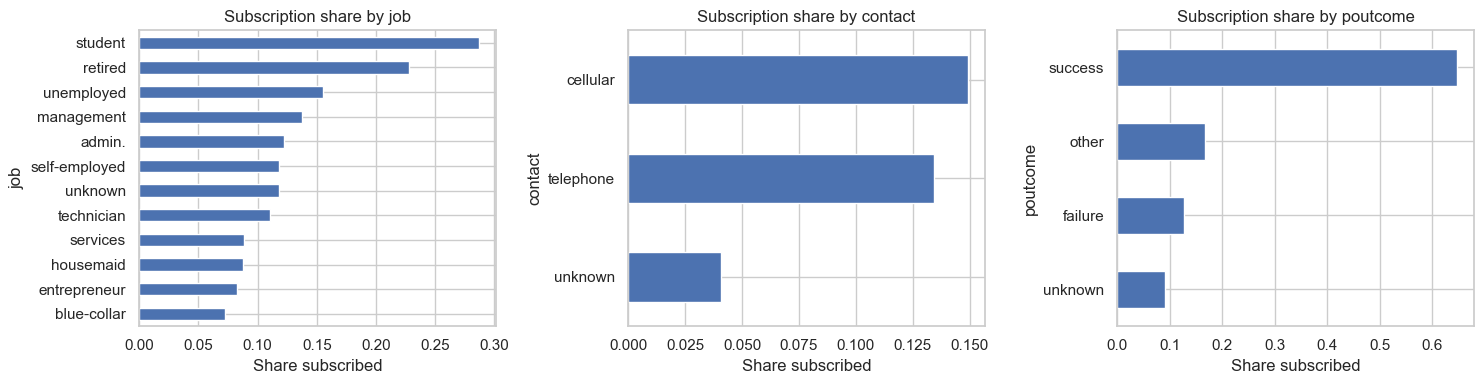

In [3]:
num=df.select_dtypes(include='number').columns.tolist()
cat=df.select_dtypes(exclude='number').columns.tolist()
# Target balance
sns.countplot(data=df, x='y', order=['no','yes']); plt.title('Target distribution'); plt.show()
print(f"Positive class share: {(df.y=='yes').mean():.1%}; accuracy alone can be misleading.")
# Numeric distributions and IQR outlier counts
display(df[num].describe().T)
rows=[]
for c in num:
 q1,q3=df[c].quantile([.25,.75]); iqr=q3-q1
 rows.append((c,int(((df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr)).sum())))
display(pd.DataFrame(rows,columns=['numeric feature','IQR flagged rows']).set_index('numeric feature'))
df[num].hist(bins=30,figsize=(14,10)); plt.suptitle('Numeric feature distributions'); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(5,2,figsize=(14,20))
for ax,c in zip(axs.flat,cat): sns.countplot(data=df,y=c,order=df[c].value_counts().head(15).index,ax=ax,color='steelblue'); ax.set_title(c)
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(4,2,figsize=(13,13))
for ax,c in zip(axs.flat,num): sns.boxplot(x=df[c],ax=ax,showfliers=False); ax.set_title(c)
plt.tight_layout(); plt.show()
sns.heatmap(df[num].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0); plt.title('Numeric correlations'); plt.show()
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,c in zip(axs,['job','contact','poutcome']):
 rate=df.groupby(c,observed=False).y.apply(lambda s:(s=='yes').mean()).sort_values()
 rate.plot.barh(ax=ax); ax.set_title('Subscription share by '+c); ax.set_xlabel('Share subscribed')
plt.tight_layout(); plt.show()


**EDA interpretation:** use the charts and displayed tables to describe class imbalance, skew, correlation, and differences in subscription shares. These are associations, not causal effects. IQR outliers are retained unless they can be shown to be data errors; `pdays=-1` is a documented sentinel.

## 3. Preprocessing and data split
At the student's request, we use a stratified 80/20 split. This differs from the teacher rubric's standard 70/30 split. Imputation, one-hot encoding, and scaling are placed inside pipelines, so they are fitted from training folds only. Exact duplicates are removed from a modeling copy, leaving the original data unchanged. No outlier removal is applied because extreme values can be real.

In [4]:
model_df=df.drop_duplicates().copy()
X=model_df.drop(columns=['y','duration']) # duration unavailable for pre-call decisions
y=(model_df.y=='yes').astype(int)
num_features=X.select_dtypes(include='number').columns.tolist()
cat_features=X.select_dtypes(exclude='number').columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print('Train/test:',X_train.shape,X_test.shape,'| model features:',X.shape[1])
num_pipe=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
cat_pipe=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
prep=ColumnTransformer([('numeric',num_pipe,num_features),('categorical',cat_pipe,cat_features)],sparse_threshold=0)


Train/test: (36168, 15) (9043, 15) | model features: 15


## 4. Baseline, models, and tuning
The majority-class DummyClassifier is the baseline. We compare six classifiers: Logistic Regression, Decision Tree, Random Forest, SVM, KNN, and HistGradientBoosting. A small logistic-regression C grid is selected by stratified three-fold cross-validation using average precision. Test data is reserved for final evaluation.

In [5]:
estimators={
 'Majority baseline':DummyClassifier(strategy='most_frequent'),
 'Logistic Regression':LogisticRegression(max_iter=1500,class_weight='balanced',random_state=42),
 'Decision Tree':DecisionTreeClassifier(class_weight='balanced',min_samples_leaf=10,random_state=42),
 'Random Forest':RandomForestClassifier(n_estimators=250,min_samples_leaf=3,class_weight='balanced_subsample',n_jobs=-1,random_state=42),
 'Linear SVM':LinearSVC(C=1,class_weight='balanced',random_state=42,max_iter=3000),
 'KNN':KNeighborsClassifier(n_neighbors=15,weights='distance'),
 'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=150,learning_rate=.1,random_state=42)}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
tune=GridSearchCV(Pipeline([('prep',prep),('model',estimators['Logistic Regression'])]),
 {'model__C':[.1,1,10]},scoring='average_precision',cv=cv,n_jobs=-1)
tune.fit(X_train,y_train)
print('Tuned logistic parameter:',tune.best_params_,'CV average precision:',round(tune.best_score_,4))
fitted={}
for name,est in estimators.items():
 if name=='Logistic Regression': fitted['Logistic Regression (tuned)']=tune.best_estimator_; continue
 p=Pipeline([('prep',prep),('model',est)]); p.fit(X_train,y_train); fitted[name]=p


Tuned logistic parameter: {'model__C': 0.1} CV average precision: 0.399


## 5. Test evaluation and comparison
We report accuracy, precision, recall/sensitivity, specificity, F1, ROC-AUC, and PR-AUC (average precision). PR-AUC is useful with the minority positive class. Confusion matrices use class order no, yes.

In [6]:
def score_values(model, Xv):
 if hasattr(model,'predict_proba'): return model.predict_proba(Xv)[:,1]
 return model.decision_function(Xv)
rows=[]; preds={}; scores={}
for name,m in fitted.items():
 pred=m.predict(X_test); score=score_values(m,X_test) if name!='Majority baseline' else np.zeros(len(y_test))
 preds[name]=pred; scores[name]=score
 tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
 rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),
 'Recall':recall_score(y_test,pred,zero_division=0),'Specificity':tn/(tn+fp),'F1':f1_score(y_test,pred,zero_division=0),
 'ROC-AUC':roc_auc_score(y_test,score) if len(np.unique(score))>1 else np.nan,
 'PR-AUC':average_precision_score(y_test,score)})
results=pd.DataFrame(rows).set_index('Model').sort_values('PR-AUC',ascending=False)
display(results.style.format('{:.3f}'))


,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
Model,,,,,,,
HistGradientBoosting,0.896,0.655,0.232,0.984,0.342,0.803,0.464
Random Forest,0.879,0.483,0.474,0.933,0.478,0.803,0.452
Logistic Regression (tuned),0.754,0.268,0.635,0.770,0.377,0.772,0.409
Linear SVM,0.758,0.268,0.620,0.776,0.375,0.772,0.405
KNN,0.893,0.652,0.177,0.987,0.278,0.737,0.381
Decision Tree,0.737,0.240,0.578,0.758,0.339,0.718,0.341
Majority baseline,0.883,0.000,0.000,1.000,0.000,nan,0.117


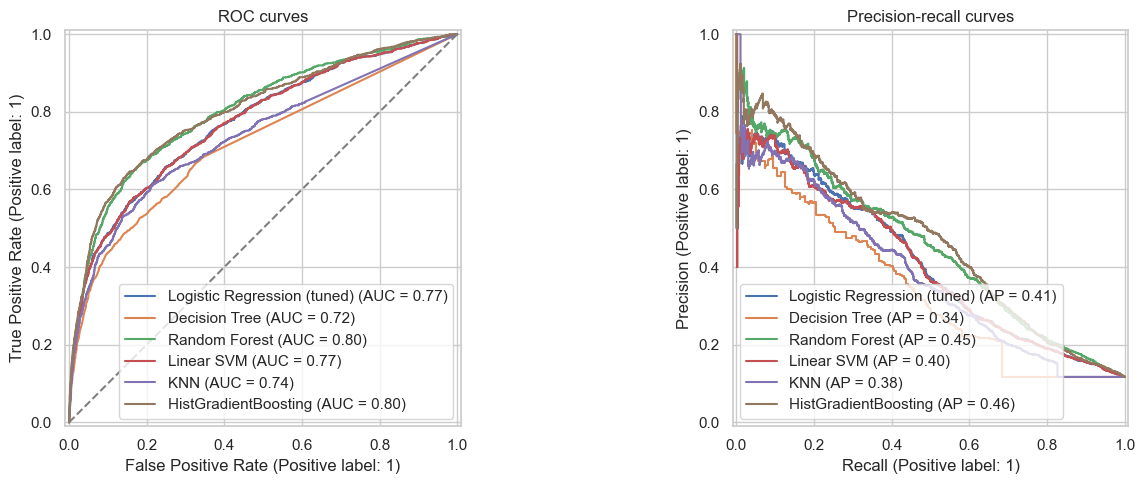

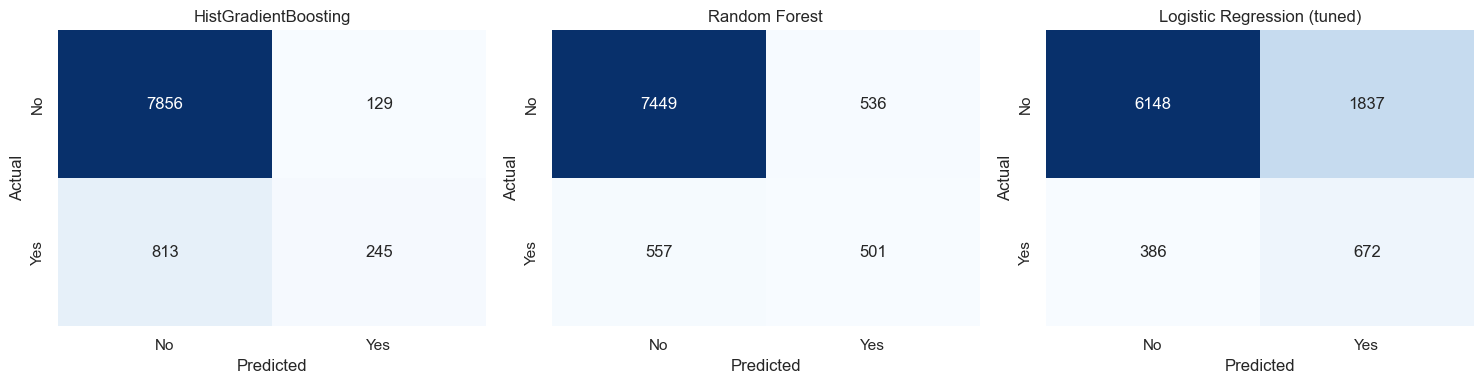

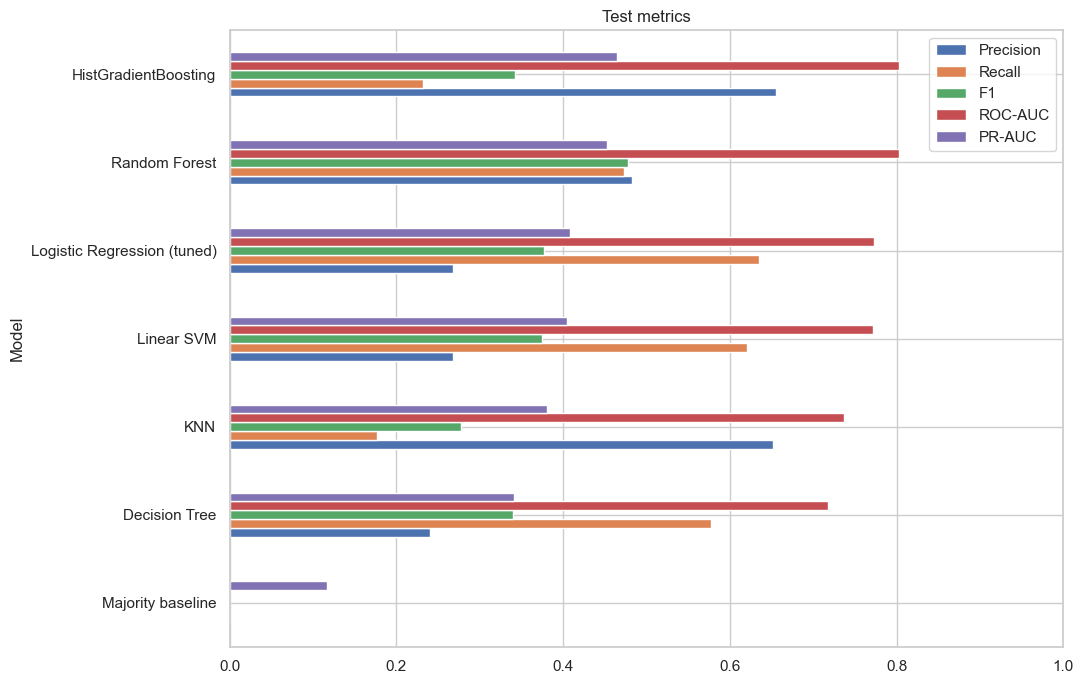

In [7]:
fig,axs=plt.subplots(1,2,figsize=(14,5))
for name in fitted:
 if len(np.unique(scores[name]))>1:
  RocCurveDisplay.from_predictions(y_test,scores[name],name=name,ax=axs[0])
  PrecisionRecallDisplay.from_predictions(y_test,scores[name],name=name,ax=axs[1])
axs[0].plot([0,1],[0,1],'--',color='gray'); axs[0].set_title('ROC curves'); axs[1].set_title('Precision-recall curves'); plt.tight_layout(); plt.show()
top=[n for n in results.index if n!='Majority baseline'][:3]
fig,axs=plt.subplots(1,len(top),figsize=(5*len(top),4))
if len(top)==1: axs=[axs]
for ax,name in zip(axs,top):
 sns.heatmap(confusion_matrix(y_test,preds[name],labels=[0,1]),annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax)
 ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_xticklabels(['No','Yes']); ax.set_yticklabels(['No','Yes'])
plt.tight_layout(); plt.show()
results[['Precision','Recall','F1','ROC-AUC','PR-AUC']].sort_values('PR-AUC').plot.barh(figsize=(11,7),xlim=(0,1),title='Test metrics'); plt.tight_layout(); plt.show()


## 6. Feature importance
Permutation importance estimates how much test PR-AUC falls when one input feature is shuffled. This is a model interpretation aid, not a causal claim.

,mean PR-AUC decrease
poutcome,0.139406
month,0.107562
contact,0.080396
day,0.050417
pdays,0.027161
housing,0.021625
age,0.018976
campaign,0.011327
marital,0.008473
balance,0.004984


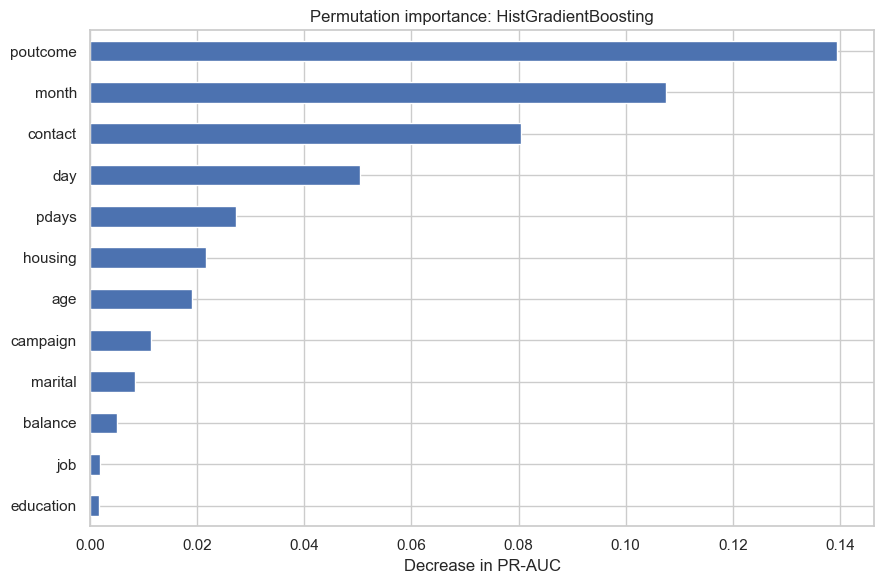

In [8]:
best=next(n for n in results.index if n!='Majority baseline')
imp=permutation_importance(fitted[best],X_test,y_test,scoring='average_precision',n_repeats=5,random_state=42,n_jobs=-1)
importance=pd.Series(imp.importances_mean,index=X_test.columns).sort_values(ascending=False)
display(importance.to_frame('mean PR-AUC decrease'))
importance.head(12).sort_values().plot.barh(figsize=(9,6),title='Permutation importance: '+best); plt.xlabel('Decrease in PR-AUC'); plt.tight_layout(); plt.show()


## 7. Results and answers
The next cell prints answers from the measured holdout results; do not report values other than those produced by running the notebook. A higher recall identifies more subscribers but may also increase false positives. Choose a model in light of campaign capacity and the precision-recall trade-off.

**Limitations:** one random historical split may not represent future campaigns or other banks; the task is predictive, not causal. The `duration` feature is excluded for realistic pre-call use. `unknown` categories and IQR-flagged values are retained. Thresholds are not optimized for campaign costs; external/time-based validation and fresh data are future improvements.


In [9]:
winner=next(n for n in results.index if n!='Majority baseline')
print('Q1 Can pre-call information predict subscription?')
print(f"Best classifier {winner}: test PR-AUC={results.loc[winner,'PR-AUC']:.3f}, F1={results.loc[winner,'F1']:.3f}, recall={results.loc[winner,'Recall']:.3f}; positive prevalence={y_test.mean():.3f}.")
print('Q2 Best model by PR-AUC:',winner)
print('Q3 Five highest permutation-importance features:',', '.join(importance.head(5).index))
print('Compare against baseline:'); display(results.loc[['Majority baseline',winner],['Accuracy','Recall','F1','PR-AUC']])
# Preserve the split for repeatable follow-up analysis; original CSV stays unchanged.
train_export=X_train.copy(); train_export['y']=y_train.values
test_export=X_test.copy(); test_export['y']=y_test.values
Path('Dataset').mkdir(exist_ok=True)
train_export.to_csv('Dataset/train_split.csv',index=False)
test_export.to_csv('Dataset/test_split.csv',index=False)
results.to_csv('model_comparison.csv')
print('Saved train and held-out test partitions in Dataset/, plus model_comparison.csv.')


Q1 Can pre-call information predict subscription?
Best classifier HistGradientBoosting: test PR-AUC=0.464, F1=0.342, recall=0.232; positive prevalence=0.117.
Q2 Best model by PR-AUC: HistGradientBoosting
Q3 Five highest permutation-importance features: poutcome, month, contact, day, pdays
Compare against baseline:


,Accuracy,Recall,F1,PR-AUC
Model,,,,
Majority baseline,0.883003,0.000000,0.000000,0.116997
HistGradientBoosting,0.895831,0.231569,0.342179,0.464494


Saved train and held-out test partitions in Dataset/, plus model_comparison.csv.


## 8. Try a prediction yourself
Run the code cell below after the training cells have finished. It will show a text prompt. Paste one customer as a JSON object, using all 15 input fields (numbers for numeric fields and quoted text for categories). The example is based on a held-out row; edit its values to try another case. Do not include `y` or `duration`. Run this cell again to test another customer.

In [ ]:
import json

example_customer = json.loads(X_test.iloc[[0]].to_json(orient='records'))[0]
print('Example input (edit the values to try another customer):')
print(json.dumps(example_customer))
customer_text = input('Paste one customer JSON object, then press Enter: ')
try:
    customer = json.loads(customer_text)
    if not isinstance(customer, dict):
        raise ValueError('Enter one JSON object.')
    missing = sorted(set(X.columns) - set(customer))
    extra = sorted(set(customer) - set(X.columns))
    if missing or extra:
        raise ValueError(f'Missing fields: {missing}; unexpected fields: {extra}')
    one_customer = pd.DataFrame([customer], columns=X.columns)
    predicted = best_model.predict(one_customer)[0]
    print('Prediction:', 'SUBSCRIBE (yes)' if predicted == 1 else 'NOT SUBSCRIBE (no)')
    if hasattr(best_model, 'predict_proba'):
        probability = best_model.predict_proba(one_customer)[0, 1]
        print(f'Estimated probability of subscription: {probability:.1%}')
    print('This is a model estimate, not a guarantee.')
except Exception as err:
    print('Could not make prediction:', err)


## Reproducibility
Run cells from top to bottom in the same directory as `bank-full (1).csv`. Seed 42; stratified 80/20 split (student-requested deviation from the rubric's 70/30 default); stratified 3-fold logistic tuning. Dependencies are listed in `requirements.txt`.